# 📘 **Week 13: Sentiment Analysis and Text Classification**

**Business Data and Text Mining — BA3002**  
**BS Business Analytics | Fall 2026 | Sections A and B**

---

**👨‍🏫 Dr. Usama Arshad**  
Assistant Professor (Business Analytics), FAST-NUCES Islamabad  
Director & Founder, CRADLE Lab — Computational Research in AI, Data Science, and Ledger Engineering  
[Website](https://usamajanjua.com) · [GitHub](https://github.com/usamajanjua9)

### 🎯 **Learning Goals**

- Identify an opinion, its target, and its positive, negative, or neutral label.
- Explain lexicon-based and machine learning-based sentiment analysis.
- Train introductory Naive Bayes and Logistic Regression text predictors.
- Interpret accuracy, precision, recall, F1, support, and confusion matrices.
- Inspect errors involving negation, sarcasm, mixed opinions, and unfamiliar wording.
- Connect sentiment findings to review analysis, complaint handling, and brand monitoring.

### 🧭 **Topics Covered This Week**

| Required topic | Where to study it | What you will learn |
|---|---|---|
| [Opinion and sentiment mining](#section-1) | Section 1 | Identify what is being said, about which target |
| [Positive, negative, and neutral sentiment](#section-2) | Section 2 | Apply a clear labelling policy |
| [Lexicon-based sentiment analysis](#section-3) | Section 3 | Score selected words and inspect rule limitations |
| [Machine learning-based sentiment analysis](#section-4) | Section 4 | Learn from labelled training examples without leaking test data |
| [Naive Bayes and Logistic Regression for text](#section-5) | Section 5 | Explain and compare two practical baselines |
| [Evaluating text classifiers](#section-6) | Section 6 | Read per-label metrics and error patterns |
| [Review, complaint, and brand sentiment applications](#section-7) | Section 7 | Turn checked findings into business action |

[💻 Go to the guided lab](#lab)

> The named scenarios, comments, labels, and numerical examples are synthetic teaching material. The lab is self-contained and requires no external dataset, API, or pretrained model. Its small test results demonstrate evaluation mechanics, not real-world model quality.

**Week connection:** Week 10 collected text; Week 11 prepared it; Week 12 built numerical representations. This week uses those representations to predict sentiment labels.

<a id="section-1"></a>

---

## 1. **Opinion Mining and Sentiment Analysis**

### 🔹 **1.1 What Is an Opinion?**

**Definition**  
An opinion expresses a view, judgement, preference, or evaluation about a target. Opinion mining tries to identify these views and what they refer to.

**Example**  
“The app is easy to use” evaluates the app. “The app was updated on Monday” reports an event without clearly expressing an evaluation.

**🚨 Problem**  
A sentence mentioning a company or product is not automatically an opinion about it.

**✅ Solution**  
Separate the target, the statement, and the expressed evaluation before assigning sentiment.

**Think about it:** Does “The bank offers a mobile app” express praise, criticism, or simply information?

### 🔹 **1.2 What Is Sentiment Analysis?**

**Definition**  
Sentiment analysis estimates the evaluative tone expressed in text toward a target, such as positive, negative, or neutral.

**Example**  
| Text | Target | Likely sentiment under a stated policy |
|---|---|---|
| The delivery was excellent | Delivery experience | Positive |
| My refund is overdue and support is unhelpful | Refund/support experience | Negative |
| The store opens at nine | Store information | Neutral |

An expressed opinion is not a direct measurement of a person's complete emotional state.

**🚨 Problem**  
A short label can hide uncertainty, context, and multiple targets.

**✅ Solution**  
Keep the original text and define the target and unit of analysis. Review ambiguous cases rather than treating every automatic label as certain.

### 🔹 **1.3 Sentiment Analysis Is One Text Prediction Task**

**Definition**  
Text categorization assigns a predefined label to text. Sentiment is one possible target; issue type, topic, urgency, and spam status are others.

**Example**  
“My card payment failed twice.” can have several separate labels:

| Task | Possible label |
|---|---|
| Sentiment under an experience-based policy | Negative |
| Business issue | Payment failure |
| Required handling | Payments team investigation |
| Urgency | Needs separate rules and context |

A sentiment model trained on three sentiment labels does not automatically learn issue categories.

**🚨 Problem**  
Teams sometimes use “negative” as a substitute for “urgent” or “fraud.”

**✅ Solution**  
Define and evaluate each task separately. A calmly worded security report may be more urgent than an angry comment about packaging.

### 🔹 **1.4 Document, Sentence, and Aspect Levels**

**Definition**  
Sentiment can be estimated for a whole document, a sentence, or a specific aspect within the text.

**Example**  
“The room was clean, but the Wi-Fi was terrible” contains a positive opinion about room cleanliness and a negative opinion about connectivity.

**🚨 Problem**  
One overall label may erase one of these opinions. Mixed sentiment is not necessarily neutral sentiment.

**✅ Solution**  
Use aspect-level analysis when the business needs separate improvement areas. For this introductory lab, use short comments with one intended overall target; examine mixed examples separately.

### 🔹 **1.5 Language Challenges That Affect Sentiment**

**Definition**  
Words obtain meaning from context, order, domain, and conversational setting.

**Example**  
| Challenge | Example | Why a simple method struggles |
|---|---|---|
| Negation | not helpful | Helpful alone looks positive |
| Sarcasm | Great, another failed payment | Praise word conflicts with the event |
| Domain meaning | low fees / low battery life | Low is not always good or bad |
| Mixed opinions | good product, poor delivery | Different aspects have different evaluations |
| Mixed language | service acha hai but refund slow hai | One English lexicon may miss much of the meaning |
| Missing context | That was just perfect | Could be sincere or sarcastic |

**🚨 Problem**  
Cleaning away negation or symbols can make these cases harder, not easier.

**✅ Solution**  
Preserve relevant evidence, inspect difficult examples, and measure performance on the languages and channels the business actually uses.

<a id="section-2"></a>

---

## 2. **Positive, Negative, and Neutral Labels**

### 🔹 **2.1 Define the Three Labels**

**Definition**  
Labels need a consistent operational definition so that people and models are solving the same task.

**Example**  
| Label | Policy used for the labelled lab dataset | Example |
|---|---|---|
| Positive | Clear praise, satisfaction, or favourable experience | Support was helpful |
| Negative | Clear criticism, dissatisfaction, or an explicitly adverse service event | Payment failed twice |
| Neutral | Factual information or a request without a clear favourable or adverse evaluation | Where is the order number? |

Our policy treats an explicitly failed payment as negative even if the wording is calm.

**🚨 Problem**  
Different annotation policies may label factual adverse events differently. Without a policy, disagreements appear to be model errors when they are partly definition differences.

**✅ Solution**  
Write the definitions first, include examples and boundary cases, and use the same policy for training and evaluation.

### 🔹 **2.2 Neutral Is Not the Same as Unknown**

**Definition**  
Neutral is a supported interpretation of the text. Unknown means there is insufficient evidence, language coverage, or context to decide reliably.

**Example**  
“The package weighs two kilograms” is factual. An empty string, an unreadable message, or an unfamiliar language is not automatically neutral.

**🚨 Problem**  
A lexicon with no matching words often produces a score of zero, which can be incorrectly reported as verified neutrality.

**✅ Solution**  
Track coverage and uncertainty separately. In the small lexicon demonstration, zero maps to neutral as a stated mechanical rule, while a separate match count shows when there was no lexical evidence.

### 🔹 **2.3 Mixed and Conflicting Evidence**

**Definition**  
A comment can express positive and negative opinions together. A zero net score can also result when positive and negative word weights cancel.

**Example**  
“Good product, terrible delivery” should preserve both aspects. A +2 and −2 word score sums to zero, but that arithmetic does not prove a neutral experience.

**🚨 Problem**  
Forcing mixed comments into a neutral category hides operational problems.

**✅ Solution**  
Use a mixed label, aspect labels, or an explicit overall-label rule when the dataset requires it. The main labelled lab examples avoid deliberately mixed targets; challenge examples expose this limitation.

### 🔹 **2.4 Create Trustworthy Reference Labels**

**Definition**  
Reference labels are the human-defined targets against which predictions are compared. They can contain mistakes and disagreements.

**Example**  
Two reviewers independently label the same comments, compare disagreements, clarify the policy, and record the final decision with reasons.

**🚨 Problem**  
Star ratings, emojis, or keywords are imperfect substitutes for reference labels. A five-star rating can accompany sarcastic criticism or mixed feedback.

**✅ Solution**  
Use ratings as optional weak supervision only with checks. Keep label provenance, review ambiguous cases, and distinguish verified labels from automatic predictions.

<a id="section-3"></a>

---

## 3. **Lexicon-Based Sentiment Analysis**

### 🔹 **3.1 What Is a Sentiment Lexicon?**

**Definition**  
A sentiment lexicon is a list of terms with associated polarity or strength values. A rule-based system combines matching values to produce a score or label.

**Example**  
A tiny teaching lexicon might assign:

| Word | Weight |
|---|---:|
| excellent | +2 |
| helpful | +1 |
| poor | −1 |
| terrible | −2 |

For “excellent and helpful,” the simple sum is +3.

**🚨 Problem**  
The list does not cover every expression or language. A missing term contributes no evidence under this rule.

**✅ Solution**  
Expose the matched words and weights alongside the final score. Use a domain-appropriate resource for real analysis and evaluate its behaviour.

### 🔹 **3.2 From Words to a Score and Label**

**Definition**  
A basic rule tokenizes text, looks up each token, adds the matched weights, and converts the total into a label.

**Example**  
For our demonstration: score > 0 → positive; score < 0 → negative; score = 0 → neutral. “Terrible support” contributes −2 from terrible.

**🚨 Problem**  
Threshold choices affect results. A score of zero may mean genuinely factual text, unmatched wording, or cancelling opinions.

**✅ Solution**  
Document the thresholds and retain additional fields such as the number of matches and whether both positive and negative evidence occurred.

### 🔹 **3.3 Negation and Intensity Rules**

**Definition**  
A lexicon system may adjust weights using nearby negation, intensifiers, punctuation, or other cues.

**Example**  
An immediate-negation rule can flip helpful from +1 to −1 in “not helpful.” A more capable system might also handle “not very helpful,” contrast, or repeated punctuation.

**🚨 Problem**  
The scope of negation is not always one word. Flipping every later word or ignoring sentence boundaries can create errors.

**✅ Solution**  
Keep the teaching rule narrow and explicit: only the immediately preceding token can negate a matched word. Test both supported and unsupported constructions; do not imply this covers natural language generally.

### 🔹 **3.4 Established Tools and Domain Adaptation**

**Definition**  
Established resources combine larger lexicons with additional rules. VADER is one example designed to handle sentiment cues in social-media-style text.

**Example**  
Such a tool may use capitalization, punctuation, negation, and degree modifiers as part of its scoring logic. Its scores and thresholds are not the same as the tiny sum used here.

**🚨 Problem**  
A tool that works on one writing style may perform differently on banking complaints, Roman Urdu, or technical reviews.

**✅ Solution**  
Consult the tool documentation, evaluate on the target domain, and keep its original scoring convention clear. The lab uses a transparent hand-written lexicon so every step runs offline; it is not an implementation of VADER.

### 🔹 **3.5 Strengths and Limits of Lexicon Methods**

**Definition**  
Lexicon approaches can provide an interpretable starting point without fitting a statistical model on labelled examples.

**Example**  
| Strength | Limitation |
|---|---|
| Easy to show which terms contributed | Limited vocabulary and contextual understanding |
| Can start without a labelled training set | Still needs labelled examples for evaluation |
| Predictable rules | Rules need maintenance as language changes |
| Useful baseline | Sarcasm, domain shifts, and mixed opinions remain difficult |

**🚨 Problem**  
Adjusting the dictionary repeatedly after inspecting test errors makes the test set part of development.

**✅ Solution**  
Freeze the lexicon and thresholds before final evaluation. Make changes using separate development examples, then evaluate on new held-out data.

<a id="section-4"></a>

---

## 4. **Machine Learning-Based Sentiment Analysis**

### 🔹 **4.1 Learn Patterns from Labelled Examples**

**Definition**  
Supervised learning uses example texts and their reference labels to learn a prediction rule. The fitted model assigns labels to new texts using learned feature patterns.

**Example**  
Training examples such as “helpful staff” → positive and “failed payment” → negative provide evidence about associations between wording and labels.

**🚨 Problem**  
The model does not receive a general understanding of all customer experiences. It learns only from the available examples and representation.

**✅ Solution**  
Use representative labelled data, document its limitations, and compare the model with simple baselines before relying on its predictions.

### 🔹 **4.2 Features and Targets**

**Definition**  
The feature input X represents the text numerically. The target y contains the label to predict.

**Example**  
| Item | Lab meaning |
|---|---|
| X | Comment text, then word/phrase counts or TF-IDF |
| y | negative, neutral, or positive |
| Record ID | Traceability only; excluded from the text features |
| Channel | Context for inspection; excluded from this text-only model |

Week 12's feature matrices become the inputs to the predictors in this week.

**🚨 Problem**  
Including a label name or a field derived from the true label in the input can make performance appear unrealistically strong.

**✅ Solution**  
Separate the text from label and metadata columns. Review feature construction for information that would not be available when a new comment arrives.

### 🔹 **4.3 Split Before Learning the Vocabulary**

**Definition**  
Training data teaches the model. Development data supports method choices. Test data provides an evaluation after those choices have been fixed.

**Example**  
The lab splits raw records into 36 training and 18 test comments, with 12 training and 6 test examples per label. Vocabulary and IDF are fitted only on the training portion.

**🚨 Problem**  
Fitting text features on all records before splitting leaks information about test wording. Related conversations or repeated templates across splits can also inflate results.

**✅ Solution**  
Split first. For real projects, group related records or use an appropriate time-based split. Exact-duplicate checks help but do not catch every near-duplicate. Our random stratified split is a small teaching demonstration, not a production benchmark.

### 🔹 **4.4 What a Pipeline Does**

**Definition**  
A pipeline places feature extraction and prediction into one reusable sequence. Fitting it trains the feature extractor and model using the same training data.

**Example**  
The Naive Bayes pipeline is comment → CountVectorizer → MultinomialNB. The Logistic Regression pipeline is comment → TF-IDF → LogisticRegression.

**🚨 Problem**  
Manually fitting different feature spaces for training and test data can produce incompatible columns or leakage.

**✅ Solution**  
Call `.fit(training_text, training_labels)` once, then `.predict(test_text)` without refitting. In later cross-validation, place learned preprocessing inside the pipeline used in every fold.

### 🔹 **4.5 Baselines and Fair Comparisons**

**Definition**  
A baseline is a simple reference method that a more complicated system should be compared against.

**Example**  
A majority-label baseline always predicts the label most common in the training data. With the balanced three-label lab split, it gets 6 of 18 test labels correct: accuracy = 1/3.

**🚨 Problem**  
A model can appear useful compared with chance but still fail on important negative comments or particular channels.

**✅ Solution**  
Evaluate the same held-out records with the same label order and metrics. The lab compares full pipelines: differences between Naive Bayes and Logistic Regression reflect both their model and their feature weighting choices.

<a id="section-5"></a>

---

## 5. **Naive Bayes and Logistic Regression for Text**

### 🔹 **5.1 Naive Bayes: Prior Plus Word Evidence**

**Definition**  
Naive Bayes uses a prior probability for each label and the likelihood of the observed features under that label. Its simplifying assumption treats features as conditionally independent given the label.

**Example**  
For a short comment with several negative-associated words, the combined evidence may favour the negative label even when some words are unfamiliar.

**🚨 Problem**  
Natural language words are not truly independent. “Not good” illustrates why treating good alone as evidence can mislead.

**✅ Solution**  
Use Naive Bayes as a fast baseline and evaluate it. Word bigrams can preserve selected local combinations, but they do not remove the underlying modelling limitations.

### 🔹 **5.2 Multinomial Naive Bayes and Smoothing**

**Definition**  
Multinomial Naive Bayes is commonly used with nonnegative word-count features. Smoothing avoids assigning zero likelihood to a vocabulary term simply because it did not appear under one training label.

**Example**  
A simplified two-label example uses vocabulary **[good, bad]**:

| Training token totals | good | bad | Total |
|---|---:|---:|---:|
| Positive examples | 3 | 1 | 4 |
| Negative examples | 1 | 3 | 4 |

With alpha = 1, P(good | positive) = (3+1)/(4+2) = 2/3 and P(good | negative) = (1+1)/(4+2) = 1/3. The denominator adds alpha once per vocabulary term.

**🚨 Problem**  
Without smoothing, an absent term under a label may produce a zero likelihood that overwhelms other evidence.

**✅ Solution**  
Use a positive smoothing value and inspect its effect on development data. The lab uses alpha = 1. Nonnegative TF-IDF can also be used in practice, but our count-based example keeps the probabilistic intuition simple.

### 🔹 **5.3 A Small Naive Bayes Decision**

**Definition**  
A label score combines its prior with the likelihood contributions of the observed terms. Numerical implementations often add logarithms instead of multiplying many tiny values.

**Example**  
Continue the two-word example with equal priors 0.5. For “good good”: positive score = 0.5 × (2/3)² = 2/9; negative score = 0.5 × (1/3)² = 1/18. Dividing by their sum gives positive probability 0.8 under this simplified model.

**🚨 Problem**  
A model probability is not a guaranteed frequency of correctness. Strong simplifying assumptions can produce overconfident outputs.

**✅ Solution**  
Read probabilities as model outputs. Calibration requires separate evidence. The example explains the arithmetic; it is not a performance estimate for customer feedback.

### 🔹 **5.4 Logistic Regression: Weighted Text Features**

**Definition**  
Logistic Regression learns weights that connect numerical features to label scores. Despite its name, it is used here to predict categories.

**Example**  
A learned positive-label score may increase when helpful appears and decrease when unhelpful appears, depending on the training data and other features.

**🚨 Problem**  
A feature coefficient is an association within the fitted representation, not proof that the word causes a sentiment or has one universal meaning.

**✅ Solution**  
Fit the model on representative examples and inspect errors. Regularization limits overly large weights; the C parameter controls the inverse strength of that regularization.

### 🔹 **5.5 From Scores to Probabilities**

**Definition**  
For two labels, a sigmoid converts a score into a probability. For multiple mutually exclusive labels, a softmax-style calculation converts label scores into probabilities that sum to one.

**Example**  
For a two-label illustration, let the positive score z = 1. Then:

**P(positive) = 1 / (1 + exp(−z)) ≈ 0.731**.

The three-label model in this lab predicts the label with the largest model probability. It does not use the binary 0.5 rule to assign every label independently.

**🚨 Problem**  
A probability of 0.73 does not establish that 73% of similar business comments are correctly labelled without calibration evidence.

**✅ Solution**  
Keep probability and certainty separate. If an operational review threshold is needed, choose and validate it on development data rather than inventing one from the test results.

### 🔹 **5.6 Compare the Two Approaches**

**Definition**  
Both methods can work with sparse text features, but they learn their decision rules differently.

**Example**  
| Question | Multinomial Naive Bayes | Logistic Regression |
|---|---|---|
| Learning idea | Combine label priors and feature likelihoods | Learn weights that separate labels |
| Lab representation | Word and bigram counts | Word and bigram TF-IDF |
| Typical benefit | Fast and simple baseline | Flexible linear decision rule |
| Important setting | Smoothing alpha | Regularization strength C |
| Common limitation | Independence assumptions, probability calibration | Limited context unless represented in features |
| Required evidence | Held-out metrics and error review | Held-out metrics and error review |

**🚨 Problem**  
There is no guarantee that one will be best across datasets. A small sample can reverse the ranking by chance.

**✅ Solution**  
Compare full methods on the same evaluation set and inspect category-level performance. To isolate the learning algorithm alone, hold the representation fixed in a separate experiment.

<a id="section-6"></a>

---

## 6. **Evaluating Text Predictors**

### 🔹 **6.1 Confusion Matrix: Where Did the Predictions Go?**

**Definition**  
A confusion matrix counts actual labels against predicted labels. We use actual labels as rows and predicted labels as columns.

**Example**  
Illustrative matrix, independent of the executed lab:

| Actual / predicted | Negative | Neutral | Positive |
|---|---:|---:|---:|
| Negative | 4 | 1 | 1 |
| Neutral | 1 | 4 | 1 |
| Positive | 0 | 1 | 5 |

The diagonal contains 13 correct predictions out of 18. The negative row shows that two negative examples were missed.

**🚨 Problem**  
Reading the axes backwards swaps the meaning of missed examples and false alarms.

**✅ Solution**  
Label both axes, fix the label order, and inspect row and column totals. A good-looking overall score can hide one poorly handled label.

### 🔹 **6.2 Accuracy and Its Limits**

**Definition**  
Accuracy is the number of correct predictions divided by the total number evaluated.

**Example**  
For the illustrative matrix, accuracy = (4+4+5)/18 = 13/18 ≈ 72.2%. If 95 of 100 comments were neutral, always predicting neutral would score 95% while detecting no negative comments.

**🚨 Problem**  
Accuracy can be dominated by a frequent label and does not tell us which errors matter.

**✅ Solution**  
Report label counts, a baseline, and per-label measures alongside accuracy. Select measures that match business costs, not just whichever number looks largest.

### 🔹 **6.3 Precision and Recall for One Label**

**Definition**  
For a chosen label, precision asks how many predictions of that label were correct; recall asks how many actual examples of that label were found.

**Example**  
Treat **negative** as the label of interest in the illustrative matrix:

- True positives, TP = 4: actual negative, predicted negative.
- False positives, FP = 1: a neutral comment predicted negative.
- False negatives, FN = 2: negative comments predicted neutral or positive.
- Precision = TP/(TP+FP) = 4/5 = **0.80**.
- Recall = TP/(TP+FN) = 4/6 ≈ **0.667**.

Here, “positive” in **true positive** means a correct detection of the target label—even when that label is negative sentiment.

**🚨 Problem**  
High precision can coexist with poor recall: the system might flag only a few obvious complaints and miss many others.

**✅ Solution**  
For complaint detection, inspect missed negatives as well as false alarms. Choose an operating policy using actual review capacity and the cost of missed issues.

### 🔹 **6.4 F1 and Support**

**Definition**  
F1 is the harmonic mean of precision and recall: **2PR/(P+R)**. Support is the number of actual evaluation examples for a label.

**Example**  
For negative sentiment above: F1 = 2×0.80×(2/3)/(0.80+2/3) ≈ **0.727**. Support is 6, the total of the negative row.

**🚨 Problem**  
F1 ignores true negatives and does not directly encode business cost. Small support makes estimates unstable.

**✅ Solution**  
Always read support with the score. State how undefined precision or recall is handled; the lab uses zero for undefined metric divisions so all methods can be displayed consistently.

### 🔹 **6.5 Macro, Weighted, and Micro Averages**

**Definition**  
An average combines label-level results, but different averaging rules answer different questions.

**Example**  
| Average | How it is formed | Interpretation |
|---|---|---|
| Macro F1 | Mean of the individual label F1 scores | Gives each label equal weight |
| Weighted F1 | Mean weighted by actual label support | Gives frequent labels more influence |
| Micro | Aggregate counts before calculating the metric | For this single-label task with all labels included, micro precision/recall/F1 equal accuracy |

Macro F1 is not the F1 calculated from macro precision and macro recall.

**🚨 Problem**  
An aggregate metric may conceal a weak negative category. A weighted average may still look good when a rare but important category is missed.

**✅ Solution**  
Use macro F1 for a balanced view across labels, then inspect each label and the confusion matrix. In this balanced test sample, weighted and macro F1 coincide because supports are equal.

### 🔹 **6.6 Data Leakage, Tuning, and Honest Testing**

**Definition**  
A test set is useful only when its labels and text have not guided model fitting or repeated design choices.

**Example**  
A vocabulary learned from all text, an identical conversation on both sides of a split, or a lexicon edited after test inspection can contaminate evaluation.

**🚨 Problem**  
Repeatedly trying settings until the test score rises turns the test set into development data.

**✅ Solution**  
Split before fitting, group related records where appropriate, use validation or cross-validation for settings, and reserve a final test. In this notebook the model settings and lexicon are fixed; test errors are discussed without retraining to improve them.

### 🔹 **6.7 Error Analysis and Deployment Monitoring**

**Definition**  
Error analysis reads the actual mistakes to identify failures that a summary metric cannot explain.

**Example**  
Compare true and predicted labels for negation, sarcasm, unusual phrases, requests, or channel-specific wording. In a real deployment, also monitor language coverage and changing label distributions.

**🚨 Problem**  
A model that works on short written reviews may fail on long complaint threads or Roman Urdu messages. A few high probabilities can hide systematic failures.

**✅ Solution**  
Record error types and gather new development data. Monitor drift and review severe cases. Do not claim a tiny synthetic holdout establishes readiness for operational use.

<a id="section-7"></a>

---

## 7. **Business Applications**

### 🔹 **7.1 Product and Service Reviews**

**Definition**  
Review sentiment can help organize feedback and surface areas for closer investigation.

**Example**  
An e-commerce team separates comments about product quality from delivery experience, then reads negative examples for each aspect.

**🚨 Problem**  
A single review may praise the item and criticize delivery. An overall sentiment label cannot reliably identify which team should act.

**✅ Solution**  
Combine sentiment with aspect or issue information, preserve evidence, and check whether each suggested issue is supported. Compare products only across suitable sources and periods.

### 🔹 **7.2 Complaint Handling and Service Recovery**

**Definition**  
Complaint analysis can prioritize review queues and route messages when combined with issue and severity information.

**Example**  
“My payment failed and money was deducted” may need payments investigation. “The agent was rude” concerns a different service process, even though both may be negative.

**🚨 Problem**  
Negativity is not the same as urgency or financial risk. Calm requests can contain serious incidents.

**✅ Solution**  
Use separate policy checks for critical issues, evaluate negative-label recall, and let staff inspect original text. Do not automatically reject, close, or penalize a customer based only on sentiment.

### 🔹 **7.3 Brand Sentiment and Social Listening**

**Definition**  
Brand sentiment analysis studies evaluative language about a named brand across selected channels and periods.

**Example**  
A campaign team monitors unique relevant posts before and after a launch, then examines which product features or experiences drive observed changes.

**🚨 Problem**  
Reposts, bots, unrelated uses of a name, changing coverage, and sarcastic posts can distort totals.

**✅ Solution**  
Verify the target brand, track unique records and collection coverage, inspect samples, and report the denominator. A change in observed sentiment does not by itself prove the campaign caused it.

### 🔹 **7.4 Report Rates with Clear Denominators**

**Definition**  
A sentiment share is a count divided by a clearly defined population of analyzed records.

**Example**  
In an illustrative set of 200 eligible, unique comments, 60 are predicted negative: predicted-negative share = 60/200 = **30%**. This is not automatically the fraction of all customers who are dissatisfied.

**🚨 Problem**  
Unknown-language comments, missing data, duplicate collection, and prediction errors can shift the apparent rate.

**✅ Solution**  
State the source, period, inclusion rules, total analyzed, review coverage, and model limitations. When validated human labels are available, distinguish them from model predictions.

### 🔹 **7.5 From Prediction to Business Action**

**Definition**  
A useful application connects a checked finding to an owner, a decision, and a follow-up measure.

**Example**  
| Finding to verify | Owner and investigation | Measure to monitor |
|---|---|---|
| Negative refund comments increased | Payments team checks processing records | Verified turnaround and recurring refund complaints |
| Wi-Fi criticism recurs | Hotel operations tests connectivity | Connection reliability and relevant feedback |
| A launch draws negative brand posts | Product/communications teams inspect specific claims | Issue resolution and comparable feedback samples |

The prediction is an input to investigation, not proof of the cause.

**🚨 Problem**  
A dashboard of red and green counts may encourage action on unsupported assumptions.

**✅ Solution**  
Read evidence, verify important claims using operational data, and monitor comparable outcomes after any change.

<a id="section-8"></a>

---

## 8. **Activities, Review, and Coverage**

### 🔹 **8.1 Label Before You Model**

Apply the stated sentiment policy and explain the target:

1. “The staff were helpful.”
2. “The payment failed twice.”
3. “Where can I download the receipt?”
4. “The product is great, but support is terrible.”
5. “Amazing, the app crashed again.”

<details><summary><strong>Reveal discussion answers</strong></summary>

1. Positive toward staff/service.
2. Negative under our adverse-event policy.
3. Neutral request under this policy.
4. Mixed aspects; do not automatically label neutral.
5. Likely negative sarcasm, but context may still need review.

</details>

### 🔹 **8.2 Work Through Evaluation**

Use the illustrative confusion matrix in section 6.1:

- Calculate negative precision, recall, and F1.
- Explain why true positive can refer to a correctly detected negative comment.
- Identify how many neutral comments were incorrectly predicted positive.
- Explain why high overall accuracy is not enough to approve complaint triage.

<details><summary><strong>Reveal answers</strong></summary>

Negative precision = 4/5 = 0.80; recall = 4/6 ≈ 0.667; F1 ≈ 0.727. True positive means correct detection of the chosen target label. One neutral comment was predicted positive. Complaint triage also needs review of missed negative or critical issues, false alarms, data coverage, and operational costs.

</details>

### 🔹 **8.3 Seven-Topic Review Checklist**

| Required topic | Theory | Practical evidence |
|---|---|---|
| Opinion and sentiment mining | 1.1–1.5 | Identify target and inspect challenge examples |
| Positive, negative, and neutral sentiment | 2.1–2.4 | Explicit annotation policy and balanced reference labels |
| Lexicon-based sentiment analysis | 3.1–3.5 | Transparent dictionary, score trace, negation rule, coverage flags |
| Machine learning-based sentiment analysis | 4.1–4.5 | Split before fitting, pipelines, and majority baseline |
| Naive Bayes and Logistic Regression for text | 5.1–5.6 | Fit and predict with both methods |
| Evaluating text classifiers | 6.1–6.7 | Accuracy, per-label precision/recall/F1, confusion matrices, error review |
| Review, complaint, and brand sentiment applications | 7.1–7.5 | Channel metadata and business interpretation exercises |

### 🔹 **8.4 Plain-Language Glossary**

| Term | Meaning |
|---|---|
| Polarity | Positive, negative, or neutral evaluation |
| Lexicon | Terms with assigned sentiment values |
| Reference label | The target assigned under a stated annotation policy |
| Prediction | A method's estimated label |
| Pipeline | Feature extraction and prediction in one reusable sequence |
| Support | Number of actual examples for a label |
| Macro F1 | Average of the individual label F1 scores |
| Leakage | Evaluation information influencing learning or design |

**Takeaway:** A useful sentiment system needs a clear target, trustworthy labels, appropriate features, honest evaluation, and review of consequential errors.

<a id="section-9"></a>

---

## 9. **Additional Reading and Resources**

- [scikit-learn: Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) — model assumptions and smoothing.
- [scikit-learn: Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) — estimator settings and outputs.
- [scikit-learn: Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html) — definitions of evaluation measures.
- [NLTK: VADER sentiment](https://www.nltk.org/api/nltk.sentiment.vader.html) — an established lexicon-and-rule implementation, distinct from our small teaching function.

The notebook uses a hand-written lexicon and embedded labelled examples. No NLTK lexicon or pretrained model download is required.

<a id="lab"></a>

---

## 💻 **LAB WEEK 13: Compare Sentiment Methods and Inspect Their Errors**

### **Goal**
Build an understandable lexicon baseline, train two text-prediction pipelines, and compare all methods on the same held-out records.

### **Setup**
Use Python 3.10 or newer. If needed, install packages in a new notebook cell:

```python
%pip install numpy pandas scikit-learn matplotlib
```

Run cells from top to bottom. The dataset is embedded. No internet is needed after installation. The final step records package versions.

### **Dataset and evaluation scope**

There are **54 synthetic English comments**, **18 per sentiment label**. Channels include reviews, complaints, and brand posts. They are deliberately short and limited in vocabulary. Human-authored labels follow section 2.1, including negative labels for explicit adverse service events. They are teaching annotations, not independently validated customer judgements.

The split is **36 training / 18 test**, stratified to retain **12 / 6 examples per label**. The split and model settings are fixed before results are inspected. No test-based tuning is performed. Do not generalize the reported scores to real customers.

### **Python reading guide**

| Code | What it means |
|---|---|
| `dictionary.get(word, 0)` | Look up a word; use zero if absent |
| `for ... in ...` | Repeat the indented steps |
| `def ...` / `return` | Define a reusable function / send back its result |
| `X_train`, `y_train` | Training text and its target labels |
| `.fit(X_train, y_train)` | Learn from training examples |
| `.predict(X_test)` | Produce labels without refitting |
| `.predict_proba(...)` | Produce model probability estimates |
| `actual != predicted` | Mark disagreements for inspection |

Keep **not** in the text. Negation is useful evidence; removing it could change the intended label.

In [1]:
from pathlib import Path  # Build portable output paths.
from importlib.metadata import version  # Record installed package versions.
import json  # Save reproducibility notes.
import re  # Split text using an explicit pattern.
import numpy as np  # Work with numeric results.
import pandas as pd  # Display records and metrics.
import matplotlib.pyplot as plt  # Draw confusion matrices.
from sklearn.model_selection import train_test_split  # Separate training and test records.
from sklearn.pipeline import Pipeline  # Keep vectorization and prediction together.
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer  # Create text features.
from sklearn.naive_bayes import MultinomialNB  # Fit a count-based text baseline.
from sklearn.linear_model import LogisticRegression  # Fit a linear text predictor.
from sklearn.dummy import DummyClassifier  # Build a majority-label baseline.
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix  # Evaluate predictions.
from IPython.display import display  # Show readable tables.
output_dir = Path("ba3002_week13_outputs")  # Keep exported results together.
output_dir.mkdir(exist_ok=True)  # Create the folder if needed.
label_order = ["negative", "neutral", "positive"]  # Fix the order used in reports and plots.
pd.set_option("display.max_colwidth", 90)  # Make short comments readable.

### **Step 1 — Load and Inspect the Labelled Examples**
Each tuple contains `(text, sentiment, channel)`. The table keeps labels and channel metadata separate from text features. Record IDs are added only for traceability. **Expected:** 54 records, with 18 in each sentiment category.

In [2]:
sample_rows = [  # Read the labels using the explicit annotation policy.
    ("The delivery was excellent", "positive", "review"),
    ("Helpful staff made shopping easy", "positive", "review"),
    ("The product quality is great", "positive", "review"),
    ("I love the reliable app", "positive", "brand_post"),
    ("Support solved my issue quickly", "positive", "complaint"),
    ("My refund arrived promptly thank you", "positive", "complaint"),
    ("The hotel room was clean and comfortable", "positive", "review"),
    ("Great service from friendly staff", "positive", "brand_post"),
    ("The payment process was easy", "positive", "review"),
    ("I am happy with the delivery", "positive", "review"),
    ("Excellent support resolved the complaint", "positive", "complaint"),
    ("The new update works well", "positive", "brand_post"),
    ("Fast delivery and good packaging", "positive", "review"),
    ("The agent was helpful and polite", "positive", "complaint"),
    ("This brand offers good value", "positive", "brand_post"),
    ("I recommend the comfortable hotel", "positive", "review"),
    ("The refund service was reliable", "positive", "complaint"),
    ("I am satisfied with the product", "positive", "brand_post"),
    ("The delivery was terrible", "negative", "review"),
    ("The staff were rude and unhelpful", "negative", "review"),
    ("The product quality is poor", "negative", "review"),
    ("I hate the unreliable app", "negative", "brand_post"),
    ("Support ignored my issue", "negative", "complaint"),
    ("My refund is overdue", "negative", "complaint"),
    ("The hotel room was dirty and uncomfortable", "negative", "review"),
    ("Bad service from rude staff", "negative", "brand_post"),
    ("The payment failed twice", "negative", "complaint"),
    ("I am disappointed with the delivery", "negative", "review"),
    ("Terrible support left the complaint unresolved", "negative", "complaint"),
    ("The new update keeps crashing", "negative", "brand_post"),
    ("Late delivery and damaged packaging", "negative", "review"),
    ("The agent was not helpful", "negative", "complaint"),
    ("This brand offers poor value", "negative", "brand_post"),
    ("I regret booking the uncomfortable hotel", "negative", "review"),
    ("The refund service was slow", "negative", "complaint"),
    ("I am unhappy with the product", "negative", "brand_post"),
    ("The delivery date is listed in the account", "neutral", "review"),
    ("The store opens at nine", "neutral", "review"),
    ("The product comes in two sizes", "neutral", "review"),
    ("The brand announced an app update", "neutral", "brand_post"),
    ("Please provide the support ticket number", "neutral", "complaint"),
    ("What is the refund policy", "neutral", "complaint"),
    ("The hotel has forty rooms", "neutral", "review"),
    ("The service desk is on the first floor", "neutral", "review"),
    ("Payment can be made by card", "neutral", "review"),
    ("Where can I check the delivery date", "neutral", "complaint"),
    ("The complaint reference is on the receipt", "neutral", "complaint"),
    ("The update was released on Monday", "neutral", "brand_post"),
    ("The packaging contains a user guide", "neutral", "review"),
    ("The agent requested my order number", "neutral", "complaint"),
    ("This brand sells products online", "neutral", "brand_post"),
    ("The hotel booking covers two nights", "neutral", "review"),
    ("Refund requests use an online form", "neutral", "complaint"),
    ("The product announcement includes a launch date", "neutral", "brand_post"),
]
data = pd.DataFrame(sample_rows, columns=["text", "sentiment", "channel"])  # Turn the labelled records into a table.
data.insert(0, "record_id", range(1, len(data) + 1))  # Assign a unique row identifier.
display(data.head(6))  # Inspect a few records and their metadata.
display(data["sentiment"].value_counts().reindex(label_order).to_frame("records"))  # Verify balanced label counts.

,record_id,text,sentiment,channel
0,1,The delivery was excellent,positive,review
1,2,Helpful staff made shopping easy,positive,review
2,3,The product quality is great,positive,review
3,4,I love the reliable app,positive,brand_post
4,5,Support solved my issue quickly,positive,complaint
5,6,My refund arrived promptly thank you,positive,complaint


,records
sentiment,
negative,18
neutral,18
positive,18


### **Step 2 — Check Records, Then Split Raw Text**
We check for empty text, invalid labels, and exact duplicates. A stratified split preserves label proportions; `random_state=42` makes the split repeatable. This does not rule out shared wording or templates: these short synthetic examples are not independent real-world evidence.

**Expected:** 36 training records and 18 test records, with 12 and 6 per label respectively.

In [3]:
assert len(data) == 54  # Confirm the intended sample size.
assert data["text"].notna().all()  # Reject missing text.
assert data["text"].str.strip().ne("").all()  # Reject blank text.
assert set(data["sentiment"]) == set(label_order)  # Confirm all three intended labels.
assert not data["text"].str.lower().duplicated().any()  # Detect exact text repeats before splitting.
train, test = train_test_split(data, test_size=1/3, random_state=42, stratify=data["sentiment"])  # Split before learning features.
train = train.reset_index(drop=True)  # Use simple row positions within the training table.
test = test.reset_index(drop=True)  # Use simple row positions within the test table.
X_train = train["text"]  # Select training text only.
y_train = train["sentiment"]  # Select training reference labels.
X_test = test["text"]  # Select held-out text only.
y_test = test["sentiment"]  # Keep held-out labels for evaluation.
split_counts = pd.DataFrame({"training": y_train.value_counts(), "test": y_test.value_counts()}).reindex(label_order)  # Count both splits.
display(split_counts)  # Expected: 12 training and 6 test examples in each row.
assert set(train["record_id"]).isdisjoint(set(test["record_id"]))  # Ensure no record is in both partitions.

,training,test
sentiment,,
negative,12,6
neutral,12,6
positive,12,6


### **Step 3 — Define a Small Sentiment Dictionary**
The dictionary is fixed before evaluating predictions. Positive numbers favour positive sentiment; negative numbers favour negative sentiment. This small teaching resource is not comprehensive and is not VADER.

In [4]:
sentiment_lexicon = {  # Assign transparent, manually chosen weights.
    "excellent": 2, "great": 2, "good": 1, "helpful": 1, "friendly": 1,
    "easy": 1, "love": 2, "reliable": 1, "happy": 1, "satisfied": 1,
    "comfortable": 1, "clean": 1, "polite": 1, "recommend": 1,
    "terrible": -2, "poor": -1, "bad": -1, "rude": -1, "unhelpful": -1,
    "hate": -2, "unreliable": -1, "dirty": -1, "uncomfortable": -1,
    "failed": -2, "disappointed": -1, "crashing": -1, "damaged": -1,
    "late": -1, "slow": -1, "overdue": -1, "ignored": -1, "unhappy": -1,
}
negation_words = {"not", "no", "never"}  # Limit the rule to explicit immediate negation.
print("Weight of helpful:", sentiment_lexicon["helpful"])  # Expected: +1.
print("Weight of terrible:", sentiment_lexicon["terrible"])  # Expected: -2.
print("Weight of an unmatched word:", sentiment_lexicon.get("receipt", 0))  # Expected: 0.

Weight of helpful: 1
Weight of terrible: -2
Weight of an unmatched word: 0


### **Step 4 — Score One Comment, One Token at a Time**
`re.findall()` returns words and sentence punctuation as separate tokens. Keeping punctuation as a token prevents our immediate-negation rule from jumping across a sentence boundary. We expand a few known negative contractions before tokenization.

The function returns the score, predicted label, match count, and a trace of contributions. **Limit:** only the immediately preceding token negates a matched word; “not very helpful” is deliberately outside that rule.

In [5]:
def score_sentiment(text):  # Define a reusable function for one comment.
    lowered = text.lower()  # Make dictionary matching case-insensitive.
    for short, expanded in {"isn't": "is not", "wasn't": "was not", "can't": "can not"}.items():  # Handle three known contractions.
        lowered = lowered.replace(short, expanded)  # Preserve their negation explicitly.
    tokens = re.findall(r"[a-z]+|[.!?;,]", lowered)  # Keep words and punctuation boundaries.
    contributions = []  # Store the numeric evidence from matched words.
    matched_terms = []  # Store readable evidence for inspection.
    for position, token in enumerate(tokens):  # Read each token together with its position.
        weight = sentiment_lexicon.get(token, 0)  # Use zero for an unmatched token.
        if weight != 0:  # Process only words in the dictionary.
            if position > 0 and tokens[position - 1] in negation_words:  # Look only one token back.
                weight = -weight  # Reverse the matched weight under this narrow rule.
            contributions.append(weight)  # Add this token's evidence.
            matched_terms.append(f"{token}: {weight:+d}")  # Keep the sign visible in the trace.
    score = sum(contributions)  # Add all matched weights.
    if score > 0:  # Interpret the score with the fixed threshold rule.
        prediction = "positive"  # More positive than negative evidence.
    elif score < 0:  # Handle the negative total.
        prediction = "negative"  # More negative than positive evidence.
    else:  # Handle both no matches and cancelling evidence.
        prediction = "neutral"  # This is a mechanical fallback, not proof of neutrality.
    mixed_evidence = any(value > 0 for value in contributions) and any(value < 0 for value in contributions)  # Identify both signs.
    return {"score": score, "prediction": prediction, "matched_words": len(contributions), "mixed_evidence": mixed_evidence, "trace": matched_terms}  # Return inspectable results.

#### Try simple examples before applying the function to a table
**Expected:** helpful → positive; not helpful → negative; a factual receipt statement → neutral with no matched words. Good plus terrible produces mixed evidence, even though the net score is negative.

In [6]:
practice_comments = ["helpful", "not helpful", "the receipt is online", "good product but terrible delivery"]  # Use controlled examples.
practice_rows = []  # Collect a result for each example.
for text in practice_comments:  # Process one comment at a time.
    result = score_sentiment(text)  # Apply the reusable scoring function.
    result["text"] = text  # Keep the original wording beside its score.
    practice_rows.append(result)  # Save the result for display.
display(pd.DataFrame(practice_rows)[["text", "score", "prediction", "matched_words", "mixed_evidence", "trace"]])  # Inspect actual contributions.

,text,score,prediction,matched_words,mixed_evidence,trace
0,helpful,1,positive,1,False,[helpful: +1]
1,not helpful,-1,negative,1,False,[helpful: -1]
2,the receipt is online,0,neutral,0,False,[]
3,good product but terrible delivery,-1,negative,2,True,"[good: +1, terrible: -2]"


### **Step 5 — Apply the Frozen Lexicon to Test Comments**
Each row receives a prediction from the same fixed rules. Keep no-match and mixed-evidence flags so that a neutral output is not mistaken for certain factual neutrality. The test labels do not modify the lexicon.

In [7]:
lexicon_results = []  # Collect one result per held-out comment.
for text in X_test:  # Preserve the test row order.
    lexicon_results.append(score_sentiment(text))  # Apply the fixed dictionary and rules.
lexicon_table = pd.DataFrame(lexicon_results)  # Convert the result dictionaries into columns.
lexicon_predictions = lexicon_table["prediction"].to_numpy()  # Extract labels for shared evaluation.
print("Test comments with no dictionary matches:", int(lexicon_table["matched_words"].eq(0).sum()))  # Show missing lexical evidence.
print("Test comments with both signs of evidence:", int(lexicon_table["mixed_evidence"].sum()))  # Show potentially mixed evidence.

Test comments with no dictionary matches: 6
Test comments with both signs of evidence: 0


### **Step 6 — Fit a Majority-Label Baseline**
This method ignores the text and always predicts the most frequent training label. Training labels tie in our balanced sample; the library's deterministic tie choice is shown below. **Expected test accuracy:** 6/18 = 0.333.

In [8]:
majority_model = DummyClassifier(strategy="most_frequent")  # Choose a deliberately simple reference method.
majority_model.fit(X_train.to_frame(), y_train)  # Learn only the training-label frequencies.
majority_predictions = majority_model.predict(X_test.to_frame())  # Produce one label per test row.
print("Always-predicted label:", majority_predictions[0])  # Reveal the tie choice rather than assuming it.
print("Baseline accuracy:", round(accuracy_score(y_test, majority_predictions), 3))  # Expected: 0.333.

Always-predicted label: negative
Baseline accuracy: 0.333


### **Step 7 — Train Naive Bayes on Word and Bigram Counts**
A pipeline first creates count features, then fits the predictor. `ngram_range=(1, 2)` includes words and adjacent two-word phrases, helping represent combinations such as **not helpful**. The examples are short single sentences; sentence-aware phrase handling is needed for longer documents.

`alpha=1.0` enables smoothing. No stop-word list is used, so negation is retained.

In [9]:
naive_bayes_pipeline = Pipeline([  # Define the feature and prediction steps in order.
    ("features", CountVectorizer(ngram_range=(1, 2), stop_words=None)),  # Learn words and bigrams from training text.
    ("model", MultinomialNB(alpha=1.0)),  # Apply count-based Naive Bayes with smoothing.
])
naive_bayes_pipeline.fit(X_train, y_train)  # Fit both steps on training records only.
nb_predictions = naive_bayes_pipeline.predict(X_test)  # Transform and predict without refitting.
print("Training vocabulary size:", len(naive_bayes_pipeline.named_steps["features"].vocabulary_))  # Report learned feature coverage.
print("First three predictions:", nb_predictions[:3])  # Preview outputs; evaluate them against labels later.

Training vocabulary size: 242
First three predictions: ['positive' 'positive' 'positive']


### **Step 8 — Train Logistic Regression on TF-IDF**
This pipeline uses the same unigram/bigram span, but weights features with TF-IDF. `max_iter=1000` allows the optimizer enough iterations; it does not mean 1,000 training documents. `C=1.0` is the fixed regularization setting for this demonstration.

We are comparing **two complete pipelines**, not isolating the learning algorithm while holding every other choice constant.

In [10]:
logistic_pipeline = Pipeline([  # Keep TF-IDF and prediction together.
    ("features", TfidfVectorizer(ngram_range=(1, 2), stop_words=None)),  # Fit vocabulary and IDF only on training text.
    ("model", LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=42)),  # Set a reproducible linear-model configuration.
])
logistic_pipeline.fit(X_train, y_train)  # Learn using training labels only.
lr_predictions = logistic_pipeline.predict(X_test)  # Predict the same held-out records.
print("Training vocabulary size:", len(logistic_pipeline.named_steps["features"].vocabulary_))  # Report the fitted features.
print("First three predictions:", lr_predictions[:3])  # Preview outputs without interpreting them as verified labels.

Training vocabulary size: 242
First three predictions: ['positive' 'positive' 'positive']


### **Step 9 — Compare All Methods on the Same Test Set**
Accuracy measures all correct predictions. Macro F1 gives each sentiment label equal weight. `zero_division=0` assigns zero when a metric denominator is zero, for example when the majority baseline never predicts positive.

The figures are calculated from the actual predictions below. They are small-sample demonstrations, not evidence that one method will be best in deployment.

In [11]:
predictions_by_method = {  # Keep each method's test predictions aligned.
    "Majority baseline": majority_predictions,
    "Teaching lexicon": lexicon_predictions,
    "Count + Naive Bayes": nb_predictions,
    "TF-IDF + Logistic Regression": lr_predictions,
}
metric_rows = []  # Store one summary row per method.
for method, predictions in predictions_by_method.items():  # Evaluate each method against the same reference labels.
    precision, recall, f1, support = precision_recall_fscore_support(y_test, predictions, labels=label_order, average="macro", zero_division=0)  # Calculate equal-label averages.
    metric_rows.append({"method": method, "accuracy": accuracy_score(y_test, predictions), "macro_precision": precision, "macro_recall": recall, "macro_f1": f1, "test_records": len(y_test)})  # Keep the denominator visible.
metrics_table = pd.DataFrame(metric_rows)  # Arrange the comparison as a table.
display(metrics_table.round(3))  # Round only for presentation, retaining full stored precision.

,method,accuracy,macro_precision,macro_recall,macro_f1,test_records
0,Majority baseline,0.333,0.111,0.333,0.167,18
1,Teaching lexicon,1.000,1.000,1.000,1.000,18
2,Count + Naive Bayes,0.167,0.167,0.167,0.167,18
3,TF-IDF + Logistic Regression,0.167,0.167,0.167,0.167,18


#### Read this run's results honestly

On the supplied fixed split:

| Method | Correct test labels | Accuracy | Macro F1 |
|---|---:|---:|---:|
| Majority baseline | 6/18 | 0.333 | 0.167 |
| Teaching lexicon | 18/18 | 1.000 | 1.000 |
| Count + Naive Bayes | 3/18 | 0.167 | 0.167 |
| TF-IDF + Logistic Regression | 3/18 | 0.167 | 0.167 |

**Interpretation:** neither trained model beats the majority baseline on accuracy. Both fail to identify any positive or negative test examples correctly in this split. Their macro F1 equals the baseline's here, but the confusion matrices show different errors.

The lexicon has been manually supplied with sentiment knowledge that matches this controlled vocabulary. Its perfect score on these 18 simple examples is **not evidence of general superiority**. The challenge examples below expose failures involving longer negation, sarcasm, and mixed opinions. The learned models receive only 36 labelled examples and have little evidence for many terms.

**Appropriate next step:** collect broader, independently labelled development data and evaluate on a new final holdout. Do not alter this test split, dictionary, or model settings just to make the displayed scores higher.

### **Step 10 — Read Per-Label Precision, Recall, F1, and Support**
Overall metrics cannot show whether a method misses negative comments. The reports below expose every label for both trained models. **Expected support:** six examples per label. A one-record error changes that label's recall by 1/6, showing how unstable a tiny sample can be.

In [12]:
for method in ["Count + Naive Bayes", "TF-IDF + Logistic Regression"]:  # Inspect the two trained methods.
    print(method)  # Identify the report being displayed.
    report = classification_report(y_test, predictions_by_method[method], labels=label_order, output_dict=True, zero_division=0)  # Request numeric report fields.
    report_table = pd.DataFrame(report).T  # Put labels and summary rows down the table.
    display(report_table.loc[label_order, ["precision", "recall", "f1-score", "support"]].round(3))  # Show only per-label values here.

Count + Naive Bayes


,precision,recall,f1-score,support
negative,0.0,0.0,0.0,6.0
neutral,0.5,0.5,0.5,6.0
positive,0.0,0.0,0.0,6.0


TF-IDF + Logistic Regression


,precision,recall,f1-score,support
negative,0.0,0.0,0.0,6.0
neutral,0.5,0.5,0.5,6.0
positive,0.0,0.0,0.0,6.0


### **Step 11 — Plot Confusion Matrices**
Rows are **actual** labels; columns are **predicted** labels. All four panels use the same label order and colour scale. Values on the diagonal are correct. Read the negative row to locate missed negatives; read the negative column to locate false alarms.

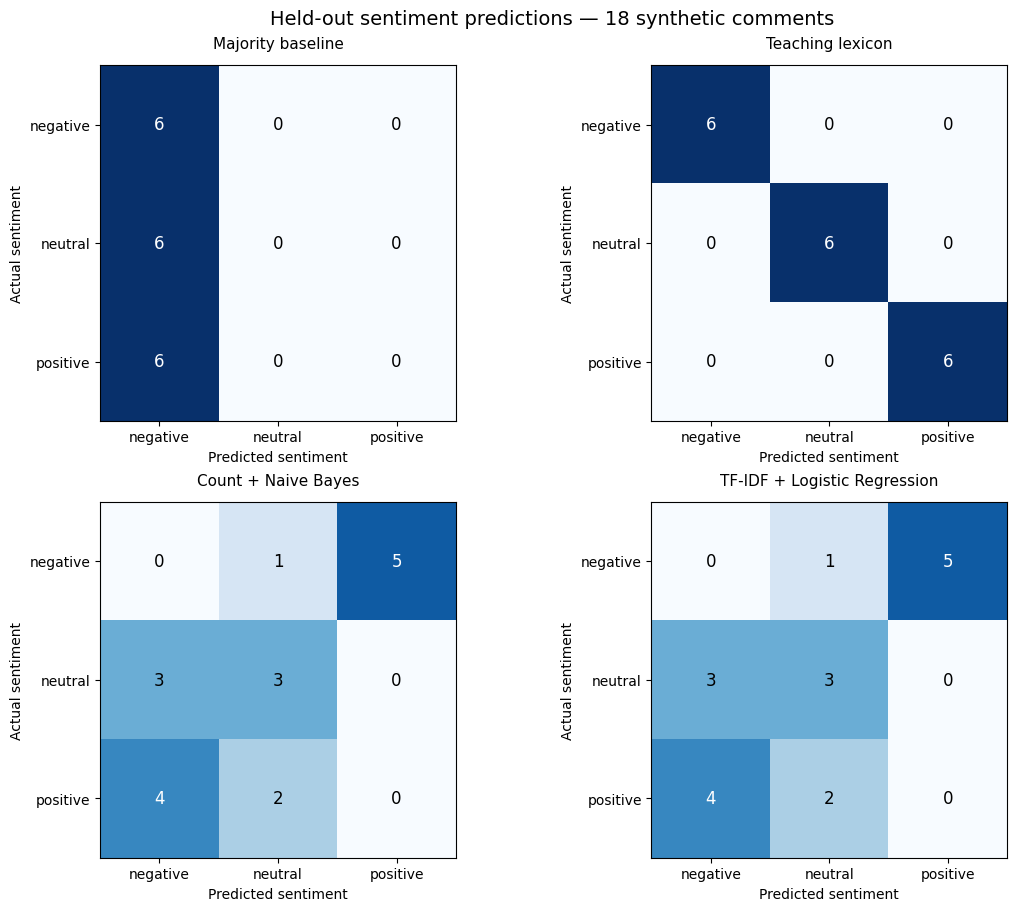

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")  # Create four readable panels.
confusion_tables = {}  # Preserve exact counts for export.
for ax, item in zip(axes.flat, predictions_by_method.items()):  # Assign one method to each panel.
    method, predictions = item  # Unpack the name and predictions.
    matrix = confusion_matrix(y_test, predictions, labels=label_order)  # Use the shared label order.
    confusion_tables[method] = pd.DataFrame(matrix, index=label_order, columns=label_order)  # Attach axis names.
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=6)  # Use identical scales; each actual label has six test examples.
    ax.set_xticks(range(3), labels=label_order)  # Label prediction columns.
    ax.set_yticks(range(3), labels=label_order)  # Label actual rows.
    ax.set_xlabel("Predicted sentiment")  # Make orientation explicit.
    ax.set_ylabel("Actual sentiment")  # Make orientation explicit.
    ax.set_title(method, fontsize=11, pad=12)  # Identify each method.
    for row in range(3):  # Visit every actual-label row.
        for column in range(3):  # Visit every predicted-label column.
            count = matrix[row, column]  # Read the count for that pair.
            color = "white" if count >= 4 else "black"  # Preserve text contrast.
            ax.text(column, row, str(count), ha="center", va="center", color=color, fontsize=12)  # Show exact counts.
fig.suptitle("Held-out sentiment predictions — 18 synthetic comments", fontsize=14)  # State the sample and scope.
fig.savefig(output_dir / "week13_confusion_matrices.png", dpi=180, bbox_inches="tight")  # Save the executed plot.
plt.show()  # Display the actual confusion matrices in the notebook.

### **Step 12 — Inspect Mistakes Beside the Original Text**
A model score does not explain an individual error. Compare each predicted label with the reference label and read the source comment. This is an error review, not permission to refit on the test data.

In [14]:
prediction_audit = test[["record_id", "text", "channel", "sentiment"]].copy()  # Preserve reference text and labels.
for method, predictions in predictions_by_method.items():  # Add every method's predictions.
    prediction_audit[method] = predictions  # Keep one prediction column per method.
errors = prediction_audit[prediction_audit["sentiment"] != prediction_audit["TF-IDF + Logistic Regression"]]  # Select Logistic Regression disagreements.
print("Logistic Regression disagreements:", len(errors), "of", len(test))  # State the denominator.
display(errors[["record_id", "text", "sentiment", "TF-IDF + Logistic Regression"]])  # Read the actual errors.
print("Naive Bayes disagreements:", int((prediction_audit["sentiment"] != prediction_audit["Count + Naive Bayes"]).sum()))  # Summarize the other model's errors.

Logistic Regression disagreements: 15 of 18


,record_id,text,sentiment,TF-IDF + Logistic Regression
0,26,Bad service from rude staff,negative,positive
1,23,Support ignored my issue,negative,positive
2,25,The hotel room was dirty and uncomfortable,negative,positive
3,10,I am happy with the delivery,positive,negative
4,3,The product quality is great,positive,negative
5,31,Late delivery and damaged packaging,negative,positive
6,48,The update was released on Monday,neutral,negative
7,50,The agent requested my order number,neutral,negative
8,33,This brand offers poor value,negative,neutral
9,16,I recommend the comfortable hotel,positive,neutral


Naive Bayes disagreements: 15


#### Investigate a concrete limitation: training-word coverage

A model cannot learn a word-specific sentiment association from a word it never saw in training. Count how many training documents contain selected words under the same analyzer. **Expected:** dirty, happy, and ignored have no training examples. Helpful appears in both a positive and a negative example, so context matters.

This is a diagnostic explanation of limited evidence, not a complete causal account of every prediction. The selected terms are inspected after evaluation; we do not use this inspection to retrain or claim a new test score.

In [15]:
coverage_rows = []  # Collect one diagnostic row per selected word.
training_analyzer = naive_bayes_pipeline.named_steps["features"].build_analyzer()  # Reuse the actual feature rules.
for word in ["dirty", "happy", "ignored", "helpful", "great", "rude"]:  # Inspect a small set of observed error-related terms.
    row = {"word": word}  # Keep the term being checked.
    for label in label_order:  # Count evidence separately for each sentiment.
        documents_with_word = 0  # Start a document count for this word and label.
        for text in train.loc[train["sentiment"].eq(label), "text"]:  # Read only training examples of that label.
            if word in training_analyzer(text):  # Count a word at most once in a document.
                documents_with_word += 1  # Record one training document containing it.
        row[label] = documents_with_word  # Attach the label-specific count.
    coverage_rows.append(row)  # Save the diagnostic row.
display(pd.DataFrame(coverage_rows))  # Inspect available training evidence without modifying either model.

,word,negative,neutral,positive
0,dirty,0,0,0
1,happy,0,0,0
2,ignored,0,0,0
3,helpful,1,0,1
4,great,0,0,1
5,rude,1,0,0


### **Step 13 — Probe Difficult Wording Without Claiming a Benchmark**
These extra comments are qualitative probes, not another labelled test set. Read how the methods respond to immediate negation, longer negation, sarcasm, mixed opinions, and neutral requests. The list was specified for teaching, not selected to improve a metric.

The largest model probability is a model output, not verified certainty. The tiny dataset cannot establish calibration.

In [16]:
challenge_texts = [  # Probe known language challenges separately from the scored test set.
    "The agent was not helpful",  # Immediate negation is supported by our lexicon rule.
    "The agent was not very helpful",  # A longer negation scope is outside that rule.
    "Great another failed payment",  # Positive wording may be sarcastic.
    "Good product but terrible delivery",  # Different aspects contain different opinions.
    "Where can I find the refund form",  # A request does not necessarily express dissatisfaction.
]
challenge_probabilities = logistic_pipeline.predict_proba(challenge_texts)  # Estimate probabilities with the already fitted model.
challenge_table = pd.DataFrame({"text": challenge_texts})  # Keep the probe wording visible.
challenge_table["lexicon"] = [score_sentiment(text)["prediction"] for text in challenge_texts]  # Apply the fixed lexical rules.
challenge_table["naive_bayes"] = naive_bayes_pipeline.predict(challenge_texts)  # Apply the fitted count model.
challenge_table["logistic_regression"] = logistic_pipeline.predict(challenge_texts)  # Apply the fitted TF-IDF model.
challenge_table["largest_model_probability"] = challenge_probabilities.max(axis=1)  # Summarize without calling it certainty.
display(challenge_table.round(3))  # Compare the actual predictions and discuss their limits.

,text,lexicon,naive_bayes,logistic_regression,largest_model_probability
0,The agent was not helpful,negative,negative,negative,0.503
1,The agent was not very helpful,positive,negative,negative,0.490
2,Great another failed payment,neutral,negative,negative,0.357
3,Good product but terrible delivery,negative,negative,negative,0.380
4,Where can I find the refund form,neutral,neutral,neutral,0.391


### **Step 14 — Verify the Workflow and Export Results**
These checks verify record separation, vocabulary fitting, prediction alignment, and narrow lexicon behaviour. They do not prove real-world reliability.

To check leakage directly, we independently build the vocabulary from **training text only** and compare it with each fitted pipeline. Test predictions must never cause the fitted vocabulary to change.

In [17]:
training_terms = set()  # Collect the features permitted by training text.
analyzer = naive_bayes_pipeline.named_steps["features"].build_analyzer()  # Reuse the configured word/bigram rules.
for text in X_train:  # Inspect training records only.
    training_terms.update(analyzer(text))  # Add their retained feature strings.
assert training_terms == set(naive_bayes_pipeline.named_steps["features"].vocabulary_)  # Verify the count vocabulary was learned from training.
assert training_terms == set(logistic_pipeline.named_steps["features"].vocabulary_)  # Verify the TF-IDF vocabulary uses the same training terms.
assert len(train) == 36 and len(test) == 18  # Verify the intended split sizes.
assert split_counts["test"].eq(6).all()  # Verify per-label test support.
for predictions in predictions_by_method.values():  # Check every evaluated method.
    assert len(predictions) == len(y_test)  # Preserve one prediction per test record.
    assert set(predictions).issubset(set(label_order))  # Allow only the three target labels.
assert score_sentiment("not helpful")["prediction"] == "negative"  # Check the explicitly supported immediate-negation rule.
assert score_sentiment("not. helpful")["prediction"] == "positive"  # Ensure negation does not jump across punctuation.
assert score_sentiment("receipt number")["matched_words"] == 0  # Confirm no-match coverage is visible.
assert np.isclose(accuracy_score(y_test, majority_predictions), 1/3)  # Check the known baseline.
print("Passed: split sizes, training-only vocabularies, label alignment, baseline, and stated lexicon rules.")  # Report actual checks.

Passed: split sizes, training-only vocabularies, label alignment, baseline, and stated lexicon rules.


In [18]:
lexicon_audit = test[["record_id", "text", "sentiment"]].join(lexicon_table)  # Keep score evidence and coverage beside test labels.
lexicon_audit["trace"] = lexicon_audit["trace"].map(json.dumps)  # Preserve each evidence list as JSON text in CSV.
lexicon_audit.to_csv(output_dir / "week13_lexicon_audit.csv", index=False)  # Save no-match and mixed-evidence flags.
train.to_csv(output_dir / "week13_training_records.csv", index=False)  # Save exact training membership.
test.to_csv(output_dir / "week13_test_records.csv", index=False)  # Save the held-out reference records.
metrics_table.to_csv(output_dir / "week13_method_metrics.csv", index=False)  # Save unrounded summary measures.
prediction_audit.to_csv(output_dir / "week13_prediction_audit.csv", index=False)  # Save predictions beside reference labels.
challenge_table.to_csv(output_dir / "week13_qualitative_probes.csv", index=False)  # Label the unscored challenge outputs separately.
for number, item in enumerate(confusion_tables.items(), start=1):  # Export each labelled confusion matrix.
    method, table = item  # Read its method name and counts.
    table.to_csv(output_dir / f"week13_confusion_{number}.csv", index_label="actual_sentiment")  # Columns are predicted labels.
package_versions = {}  # Collect versions used for this run.
for package in ["numpy", "pandas", "scikit-learn", "matplotlib"]:  # Include the main dependencies.
    package_versions[package] = version(package)  # Read the installed version.
notes = {  # Record settings needed to interpret the saved results.
    "data": "54 synthetic English comments; labels are teaching annotations",
    "split": "36 training / 18 test; stratified; random_state=42",
    "label_order": label_order,
    "lexicon": sentiment_lexicon,
    "negation_rule": "Only the immediately preceding token; punctuation boundaries retained",
    "zero_score_rule": "Neutral output; no-match and mixed-evidence flags retained during analysis",
    "naive_bayes": "Count unigrams+bigrams, alpha=1; training-only vocabulary",
    "logistic_regression": "TF-IDF unigrams+bigrams, C=1, lbfgs, max_iter=1000; training-only vocabulary and IDF",
    "metrics": "Accuracy and macro averages; undefined divisions set to zero; no test-based tuning",
    "confusion_file_method_order": list(confusion_tables),
    "limitations": "Small synthetic sample; limited wording; no real-world accuracy or calibration claim",
    "package_versions": package_versions,
}
(output_dir / "week13_method_notes.json").write_text(json.dumps(notes, indent=2), encoding="utf-8")  # Save readable provenance and settings.
print("Saved evaluation tables, split records, prediction audit, confusion plots, and notes to:", output_dir.resolve())  # Confirm the output location.

Saved evaluation tables, split records, prediction audit, confusion plots, and notes to: /workspace/scratch/811a54b07379/deliverables/ba3002_week13_outputs


### ✅ **Interpret the Results Before Making a Recommendation**

Use the **executed comparison table** to answer:

1. Which method has the highest macro F1 on these 18 examples? Does its accuracy tell the same story?
2. Which model misses more negative comments? Read the negative rows of the confusion matrices.
3. Which neutral requests are mistaken for opinions? Read the disagreement table.
4. What does the no-match count tell you about the teaching lexicon's coverage?
5. What examples would you collect next from real reviews, complaints, and brand posts?

No method is declared universally best. These are fixed, synthetic examples used to teach the complete evaluation process.

### **Small Beginner Practice**

- Call `score_sentiment("not helpful")` and read its trace.
- Compare it with `score_sentiment("not very helpful")`. Explain the narrow rule's failure.
- Use the trained pipelines to predict one new comment. Keep that prediction separate from the scored test results.
- Explain why changing the lexicon after reading test mistakes requires a new final evaluation set.

### 🛠️ **If Something Goes Wrong**

| Issue | What to do |
|---|---|
| Missing package | Run the setup installation command and restart if requested |
| `NameError` | Run earlier cells, or restart and run all cells in order |
| Indentation error | Keep the statements inside a loop or function consistently indented |
| Empty vocabulary | Check the input text and tokenization settings |
| Convergence warning | Inspect the warning and training settings; do not ignore it or tune against test labels |
| Assertion fails after changing examples | Restore the supplied dataset before checking the supplied totals |

**Final lesson:** A sentiment prediction becomes useful only when its target, evidence, limitations, and evaluation are understood.